# Simple Linear Regression Model On Salary Prediction

In [ ]:
#Importing libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [ ]:
df=pd.read_csv("/content/Salary_Data.csv")

In [ ]:
df

,YearsExperience,Salary
0,1.1,39343.0
1,1.3,46205.0
2,1.5,37731.0
3,2.0,43525.0
4,2.2,39891.0
5,2.9,56642.0
6,3.0,60150.0
7,3.2,54445.0
8,3.2,64445.0
9,3.7,57189.0


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 2 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   YearsExperience  30 non-null     float64
 1   Salary           30 non-null     float64
dtypes: float64(2)
memory usage: 612.0 bytes


In [ ]:
df.shape

(30, 2)

In [ ]:
df.describe().transpose()

,count,mean,std,min,25%,50%,75%,max
YearsExperience,30.0,5.313333,2.837888,1.1,3.20,4.7,7.70,10.5
Salary,30.0,76003.000000,27414.429785,37731.0,56720.75,65237.0,100544.75,122391.0


In [ ]:
df.isnull().sum()

,0
YearsExperience,0
Salary,0


/usr/local/lib/python3.13/dist-packages/seaborn/axisgrid.py:2100: UserWarning: The `size` parameter has been renamed to `height`; please update your code.
  warnings.warn(msg, UserWarning)


Text(-2.6805555555555483, 0.5, 'Salary')

<Figure size 1200x600 with 0 Axes>

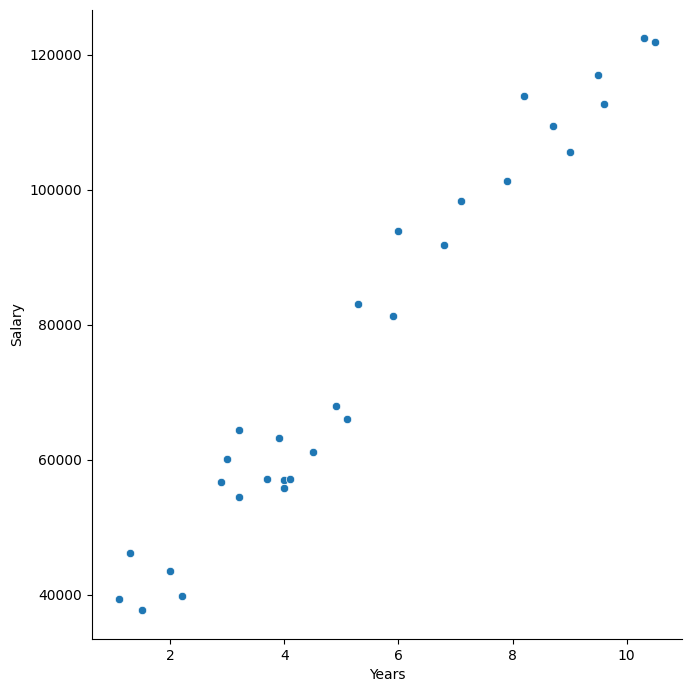

In [ ]:
#Showing how the variables are scattered
plt.figure(figsize=(12,6))
sns.pairplot(df,x_vars=['YearsExperience'],y_vars=['Salary'],size=7,kind='scatter')
plt.xlabel('Years')
plt.ylabel('Salary')

/tmp/ipykernel_1417/738670369.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df["Salary"])


<Axes: xlabel='Salary', ylabel='Density'>

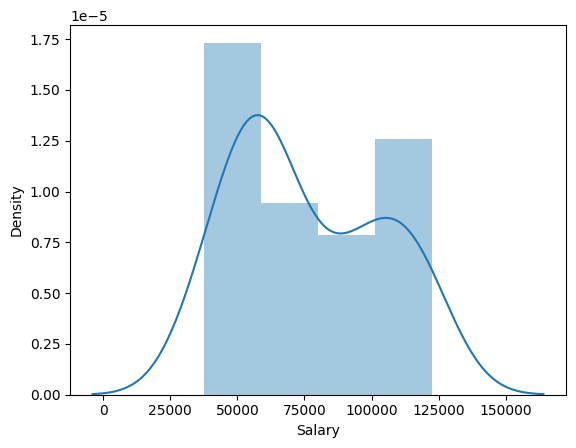

In [ ]:
sns.distplot(df["Salary"])

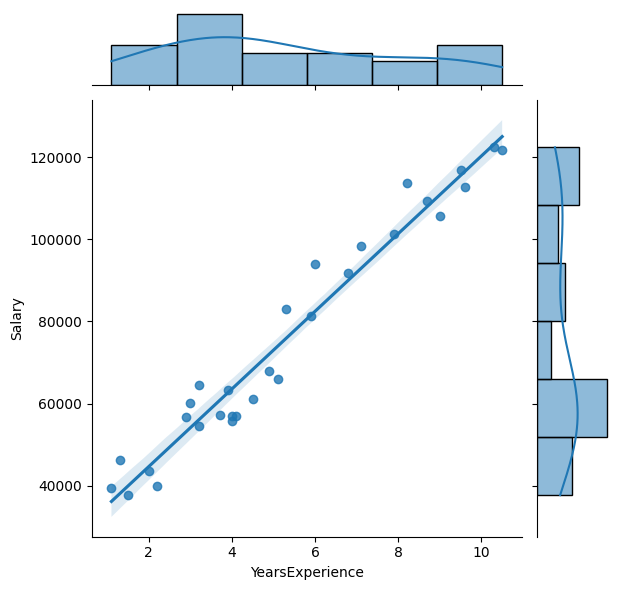

In [ ]:
#Showing a regression line
sns.jointplot(x="YearsExperience", y="Salary", kind="reg", data=df)

In [ ]:
X=df['YearsExperience']
Y=df['Salary']

In [ ]:
#Importing segregating data from scikit learn
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [ ]:
#Splitting the data for train and test
X_train,X_test,y_train,y_test = train_test_split(X,Y, train_size=0.7,random_state=100)

In [ ]:
#Fitting data to the model
model = LinearRegression()
model.fit(X_Train, y_train)

LinearRegression()

In [ ]:
X_Train = X_train.values.reshape(-1, 1)
X_Test = X_test.values.reshape(-1, 1)

In [ ]:
#Predicting the Salary for the test values
y_predict = model.predict(X_Test)
y_predict

array([ 61208.34198766, 117649.32424949, 125434.28732008,  65100.82352296,
        53423.37891707,  64127.70313914, 118622.44463331, 112783.72233036,
        54396.49930089])

Let,s check this with an example. Assume that an employee has 3.4 years of experience and we want to predict salary.`

In [ ]:
model.predict([[3.4]])

array([58288.98083619])

The predicted salary for an employee with 3.4 years is approximately 58289.

Analyzing the prediction

Text(0.5, 1.0, 'Actual vs. Predicted')

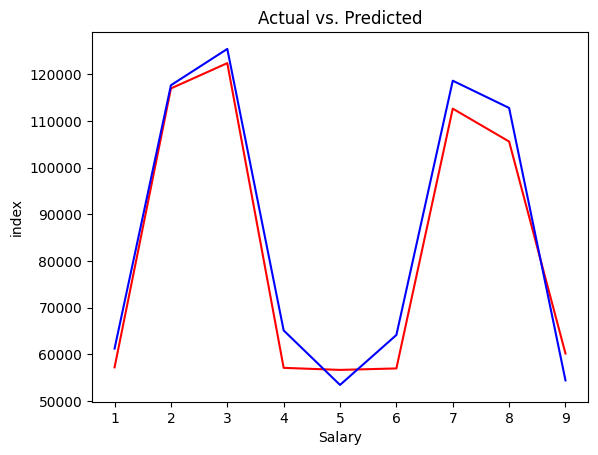

In [ ]:
#Plotting the actual and predicted values
c = [i for i in range (1,len(y_test)+1,1)]
plt.plot(c,y_test,color='r',linestyle='-')
plt.plot(c,y_predict,color='b',linestyle='-')
plt.xlabel('Salary')
plt.ylabel('index')
plt.title('Actual vs. Predicted')

In [ ]:
#Intercept and coeff of the line
print('Intercept of the model:',model.intercept_)
print('Coefficient of the line:',model.coef_)

Intercept of the model: 25202.887786154883
Coefficient of the line: [9731.20383825]


In [ ]:
print("MAE:", mean_absolute_error(y_test, y_predict))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_predict)))
print("R²:", r2_score(y_test, y_predict))

MAE: 5010.529885004953
RMSE: 5505.479002176146
R²: 0.9627668685473267
